# Small physics triggers in series 07221203_2025, dump 1

**Goal.** Find real (pulse) triggers with a *small* pulse height, as the starting point for normalising our pulses to TES current (see the note on pulse normalization). We take one dump, series `07221203_2025`, dump 1 (`07221203_2025_F0001`), and for every event measure the pulse height in every working channel. Then we histogram the **largest pulse height over all channels** of each event and choose the small-amplitude end.

**Trigger labels are swapped.** In this dump's `.csv` the label `Physics` marks the random triggers and `Unknown` marks the real (pulse) triggers; `pulse_cuts.randoms` and `pulse_cuts.real_triggers` encode this (a working assumption, see Note 2a). So "physics triggers" in the physical sense are the events labelled `Unknown`.

**Pulse height.** The first try used `pulse_quantities.max_deviation`, the largest |sample - pretrigger mean| after the 500-sample pretrigger window. It fails for small pulses: traces with a steep baseline drift have a large maximum deviation although they carry no pulse (the same problem as in Note 5), so the selection was mostly drift. Here we use a **drift-robust rise height** (section 2): fit a straight line to the pretrigger window (ending 150 us before the trigger, because the pulses start to rise before it), extend it over the first 200 samples (320 us) after the trigger, and take the largest *smoothed* excess above that line in that window. A drift continues along the line and gives no excess; a pulse rises at the trigger and does.

In [1]:
import sys
import warnings
from pathlib import Path
# Find the project's python folder from wherever this notebook is, however deep.
_here = Path.cwd().resolve()
REPO = next((p for p in [_here, *_here.parents] if (p / "python" / "pulse_io.py").exists()), None)
assert REPO, "Start Jupyter from inside the NSDF-Data folder."
sys.path.insert(0, str(REPO / "python"))

import numpy as np
import matplotlib.pyplot as plt
from nsdf_dark_matter.idx import load_all_data

import pulse_io as pio
import pulse_quantities as pq
import pulse_operations as po
import pulse_cuts as pc
import pulse_channels as pch
from pulse_config import PulseConfig

import check_environment
check_environment.check()

warnings.filterwarnings("once")
FIGDIR = Path("..") / "figures"     # the figures folder of the R76 notebooks
FIGDIR.mkdir(exist_ok=True)

Environment OK: Python 3.12.15, and the 8 packages in requirements.txt match.


## 1. Load the dump and the trigger labels

In [2]:
DUMP = "07221203_2025_F0001"          # series 07221203_2025, dump 1
config_500 = PulseConfig(pretrigger_samples=500, glitch_samples=10, sample_period_s=1.6e-6)
cdms = load_all_data(str(Path.home() / "idx" / DUMP))
det_ids = {det: pio.filter_by_detector(cdms.get_detector_ids(), det) for det in range(3)}
KEYS = [(det, ch) for det in range(3) for ch in range(4)]

trigger_types = pio.trigger_types(cdms, det_ids[0])
real = pc.real_triggers(trigger_types)       # label 'Unknown': the pulse triggers
rand = pc.randoms(trigger_types)             # label 'Physics': the random triggers
print(f"{len(trigger_types)} events: {rand.sum()} randoms (label 'Physics'), {real.sum()} real triggers (label 'Unknown')")

1517 events: 1008 randoms (label 'Physics'), 509 real triggers (label 'Unknown')


C:\Users\villanoa\AppData\Local\Temp\ipykernel_20388\2199177966.py:8: UserWarning: real_triggers is marked under_development: the other half of the randoms assumption: events recorded as 'Unknown' are taken to be real (pulse-triggered) events. Not confirmed; see `randoms`
  real = pc.real_triggers(trigger_types)       # label 'Unknown': the pulse triggers
C:\Users\villanoa\AppData\Local\Temp\ipykernel_20388\2199177966.py:9: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative to their names: events recorded as 'Physics' are taken to be randoms (fixed-count random triggers) and 'Unknown' to be real triggers. That mapping is a working assumption from 07221203_2025_F0001 (see Note 2a), not confirmed against the DAQ configuration or the nsdf library
  rand = pc.randoms(trigger_types)             # label 'Physics': the random triggers


## 2. Pulse height of every event in every channel

A channel is *dead* when its signal never changes (no readout; five of the twelve here). The other seven are the working channels.

**The drift-robust rise height.** For each trace: (1) fit a straight line to the pretrigger samples, after the first 10 glitch samples and up to 150 us (94 samples) before the trigger, because the pulses start to rise up to about 80 us before it and would otherwise tilt the line; (2) in the 200 samples after the trigger (samples 500 to 700) subtract that line, extended; (3) smooth with an 8-sample moving average to suppress the sample-to-sample noise; (4) the rise height is the largest value of the result. Unlike `max_deviation` it is signed (our pulses go up) and it only looks at the window where a pulse starts. The old `max_deviation` is kept alongside for comparison.

For the noise of each channel we use the spread of the rise height over the randoms (1.4826 times the median absolute deviation, which ignores the randoms that carry a pulse).

In [3]:
PRE_END, WIN, SMOOTH = config_500.pretrigger_samples, 200, 8   # trigger sample, window after the trigger, smoothing (samples)
FIT_END = PRE_END - 94      # the line is fitted up to here: 150 us (94 samples) before the trigger, because the pulses start to rise up to ~80 us before it

def rise_height(pulses, config=config_500, window=WIN, smooth=SMOOTH):
    """Drift-robust pulse height: largest smoothed excess above the extended pretrigger line, in the first `window` samples after the trigger (counts)."""
    pulses = np.asarray(pulses, dtype=float)
    start, g = config.pretrigger_samples, config.glitch_samples
    x_pre = np.arange(g, FIT_END)
    slope, intercept = np.polyfit(x_pre, pulses[:, g:FIT_END].T, 1)           # one line per trace
    x_win = np.arange(start, start + window + smooth - 1)
    resid = pulses[:, x_win] - (slope[:, None] * x_win + intercept[:, None])
    csum = np.cumsum(np.pad(resid, ((0, 0), (1, 0))), axis=1)
    smoothed = (csum[:, smooth:] - csum[:, :-smooth]) / smooth                # moving average, `window` values per trace
    return smoothed.max(axis=1)

amp = {}          # (det, ch) -> rise height of every event, counts
dev = {}          # (det, ch) -> max_deviation of every event, counts (the first try)
noise = {}        # (det, ch) -> noise of the rise height, from the randoms, counts
dead = []
for key in KEYS:
    _, p = pio.load_channel_batch(cdms, det_ids[key[0]], key[1])
    if np.all(p.std(axis=1) == 0):
        dead.append(key)
        continue
    amp[key] = rise_height(p)
    dev[key] = pq.max_deviation(p, config_500)
    r = amp[key][rand]
    noise[key] = 1.4826 * np.median(np.abs(r - np.median(r)))
working = list(amp)
name = lambda key: pch.channel_name(*key)
print(f"{len(working)} working channels; dead: {', '.join(name(k) for k in dead)}")
print(f"{'channel':<10}{'noise (counts)':>16}{'median height, randoms':>24}{'median, real triggers':>24}")
for key in working:
    print(f"{name(key):<10}{noise[key]:>16.2f}{np.median(amp[key][rand]):>24.1f}{np.median(amp[key][real]):>24.1f}")

A = np.array([amp[k] for k in working])                    # (channels, events)
amp_max = A.max(axis=0)                                    # largest rise height over the channels, per event
amp_max_sigma = (A / np.array([noise[k] for k in working])[:, None]).max(axis=0)   # same, in units of each channel's noise
max_channel = [working[i] for i in A.argmax(axis=0)]       # which channel carries the maximum, per event
dev_max = np.array([dev[k] for k in working]).max(axis=0)  # the first try, for comparison

7 working channels; dead: Side1pC, Side1pD, Side2pA, Side1pA, Side2pD
channel     noise (counts)  median height, randoms   median, real triggers
Side2pC               0.92                     1.7                   169.5
Side2pF               1.23                     2.0                   353.3
Side1pF               1.05                     1.8                   230.2
Side1pE               1.33                     3.1                   506.4
Side1pB               1.52                     2.8                   695.3
Side2pE               1.31                     2.6                   401.5
Side2pB               0.36                     1.2                     1.2


C:\Users\villanoa\AppData\Local\Temp\ipykernel_20388\1443076035.py:30: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  name = lambda key: pch.channel_name(*key)
C:\Users\villanoa\Research\NSDF-Data\python\pulse_channels.py:83: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return channel_info(detector, channel).name


## 3. Histogram of the largest rise height over all channels

One entry per event. Real triggers (blue) and randoms (grey) on a logarithmic height axis. The dashed line is the real triggers' largest `max_deviation` (the first try); the difference between it and the blue line is the drift.

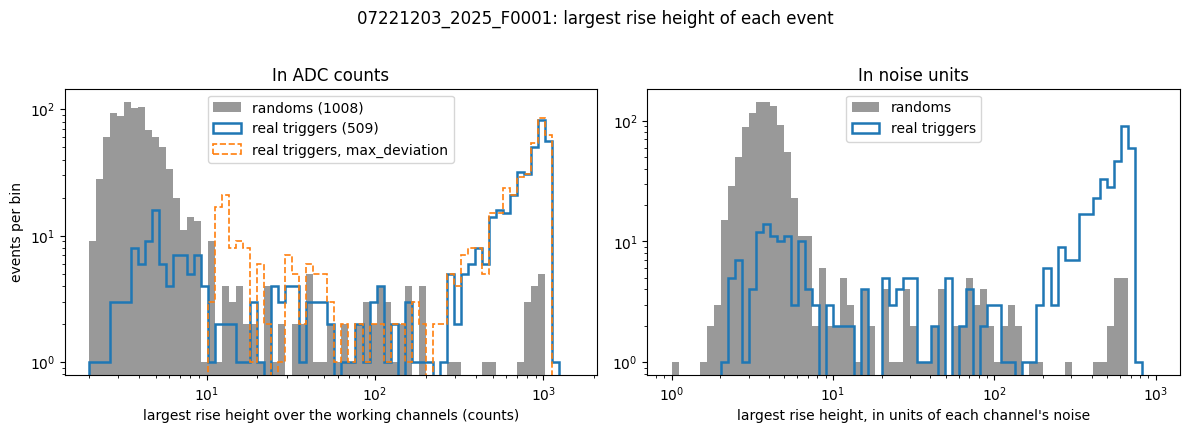

In [4]:
bins = np.logspace(np.log10(2), np.log10(1500), 70)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.hist(amp_max[rand], bins=bins, color="0.6", label=f"randoms ({rand.sum()})")
ax.hist(amp_max[real], bins=bins, histtype="step", linewidth=1.8, color="C0", label=f"real triggers ({real.sum()})")
ax.hist(dev_max[real], bins=bins, histtype="step", linewidth=1.2, linestyle="--", color="C1", label="real triggers, max_deviation")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("largest rise height over the working channels (counts)")
ax.set_ylabel("events per bin")
ax.set_title("In ADC counts")
ax.legend()

bins_s = np.logspace(np.log10(1), np.log10(1000), 70)
ax = axes[1]
ax.hist(amp_max_sigma[rand], bins=bins_s, color="0.6", label="randoms")
ax.hist(amp_max_sigma[real], bins=bins_s, histtype="step", linewidth=1.8, color="C0", label="real triggers")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("largest rise height, in units of each channel's noise")
ax.set_title("In noise units")
ax.legend()
fig.suptitle(f"{DUMP}: largest rise height of each event", y=1.02)
fig.tight_layout()
fig.savefig(FIGDIR / f"pulse-height-max-all-channels-{DUMP}.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Select the small pulses

The choice of range is made by eye from the histogram above. `AMP_LOW` must be well above the noise of the randoms (so the pulse is real); 15 counts is about three times the randoms' typical largest height over the seven channels, and `AMP_HIGH` keeps only the small end. **These two numbers are provisional; edit them and rerun.**

In [5]:
AMP_LOW, AMP_HIGH = 15.0, 200.0           # counts: provisional range for 'small pulses'

p50, p90 = np.percentile(amp_max[rand], [50, 90])
print(f"for scale: the randoms' largest rise height over the channels has median {p50:.1f} and 90th percentile {p90:.1f} counts (the tail includes randoms that carry a pulse)")
small = real & (amp_max >= AMP_LOW) & (amp_max < AMP_HIGH)
print(f"{small.sum()} of {real.sum()} real triggers have a largest rise height between {AMP_LOW:.0f} and {AMP_HIGH:.0f} counts")
chans, counts = np.unique([name(max_channel[i]) for i in np.flatnonzero(small)], return_counts=True)
print("channel with the largest rise height:", ", ".join(f"{c} {n}" for c, n in zip(chans, counts)))

for scale: the randoms' largest rise height over the channels has median 3.8 and 90th percentile 8.8 counts (the tail includes randoms that carry a pulse)
53 of 509 real triggers have a largest rise height between 15 and 200 counts
channel with the largest rise height: Side1pB 23, Side1pE 1, Side1pF 2, Side2pE 7, Side2pF 20


C:\Users\villanoa\AppData\Local\Temp\ipykernel_20388\1443076035.py:30: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  name = lambda key: pch.channel_name(*key)


### The selected events

Traces of 12 selected events spread evenly through the selection (ordered by event number), in the channel that has the largest rise height of the event, with the pretrigger line subtracted (the line used for the rise height, so a drift appears as a flat trace). The dashed line marks the trigger.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_20388\1443076035.py:30: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  name = lambda key: pch.channel_name(*key)


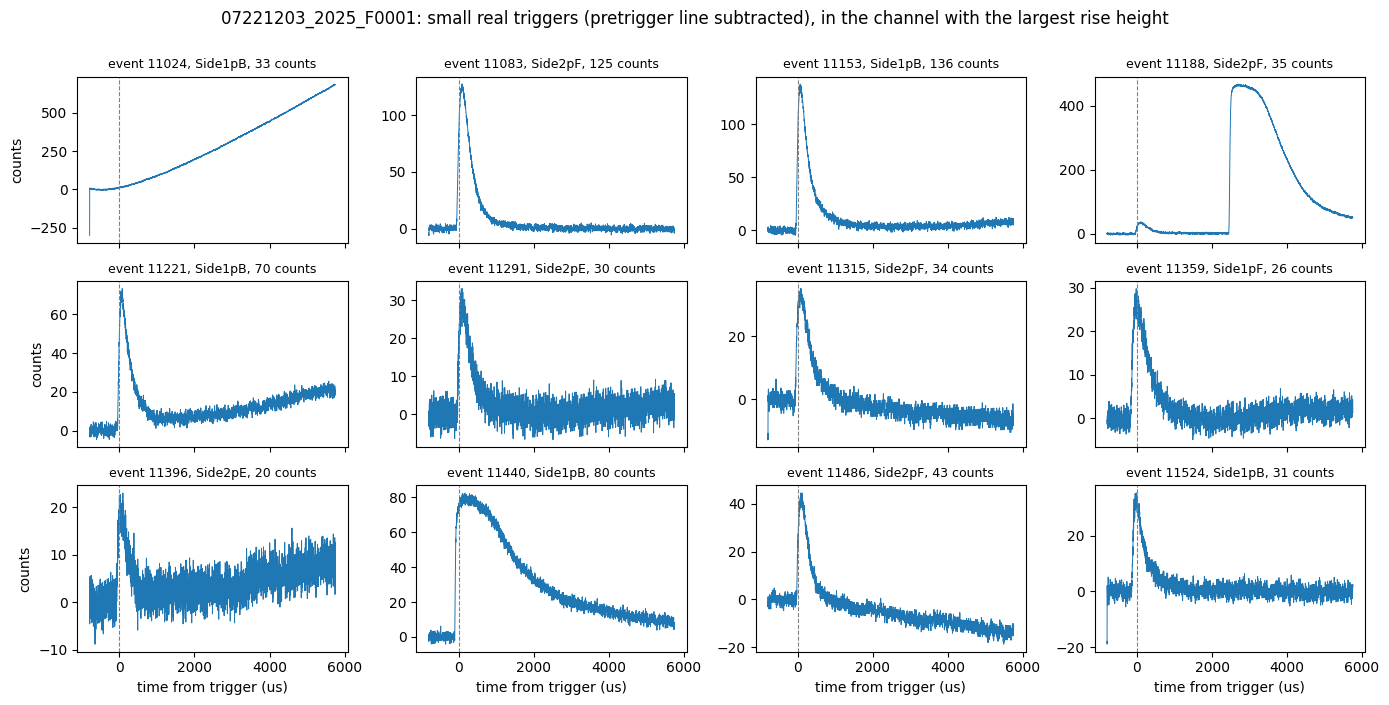

In [6]:
sel = np.flatnonzero(small)
idx = sel[np.linspace(0, len(sel) - 1, 12).astype(int)]
n_samples = 4096
t_us = (np.arange(n_samples) - config_500.pretrigger_samples) * config_500.sample_period_s * 1e6
fig, axes = plt.subplots(3, 4, figsize=(14, 7), sharex=True)
for ax, i in zip(axes.flat, idx):
    key = max_channel[i]
    _, p = pio.load_channel_batch(cdms, det_ids[key[0]], key[1])
    x = np.arange(n_samples)
    slope, intercept = np.polyfit(x[config_500.glitch_samples:FIT_END], p[i, config_500.glitch_samples:FIT_END], 1)
    ax.plot(t_us, p[i] - (slope * x + intercept), linewidth=0.7)
    ax.axvline(0, color="0.5", linestyle="--", linewidth=0.8)
    ax.set_title(f"event {pio.event_id(det_ids[0][i])}, {name(key)}, {amp_max[i]:.0f} counts", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("time from trigger (us)")
for ax in axes[:, 0]:
    ax.set_ylabel("counts")
fig.suptitle(f"{DUMP}: small real triggers (pretrigger line subtracted), in the channel with the largest rise height", y=1.0)
fig.tight_layout()
fig.savefig(FIGDIR / f"small-real-triggers-{DUMP}.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. A few selected events in all channels

For a few of the selected events, one figure each: one tile per channel (rows are the readout boards DCRC1, DCRC3 and DCRC4, columns the four channels of a board; dead channels are blank). Only the part of the trace around the pulse is drawn, and **after the sloped baseline is subtracted**: a straight line is fitted to the pretrigger samples (the grey band: glitch samples skipped, ending 150 us before the trigger) and subtracted from the whole trace, so a drift no longer hides the pulse. The dashed line is the trigger. The events are spread evenly in height through the selection; to look at particular events, put their event numbers in `EVENTS`.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_20388\1376026716.py:45: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  ax.plot(t_us[show], flat[0][show], linewidth=0.8, color="C0" if pch.channel_info(det, ch).side == 1 else "C1")
C:\Users\villanoa\AppData\Local\Temp\ipykernel_20388\1376026716.py:46: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  ax.set_title(f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc}): {amp[(det, ch)][i]:.0f} counts", fontsize=9)


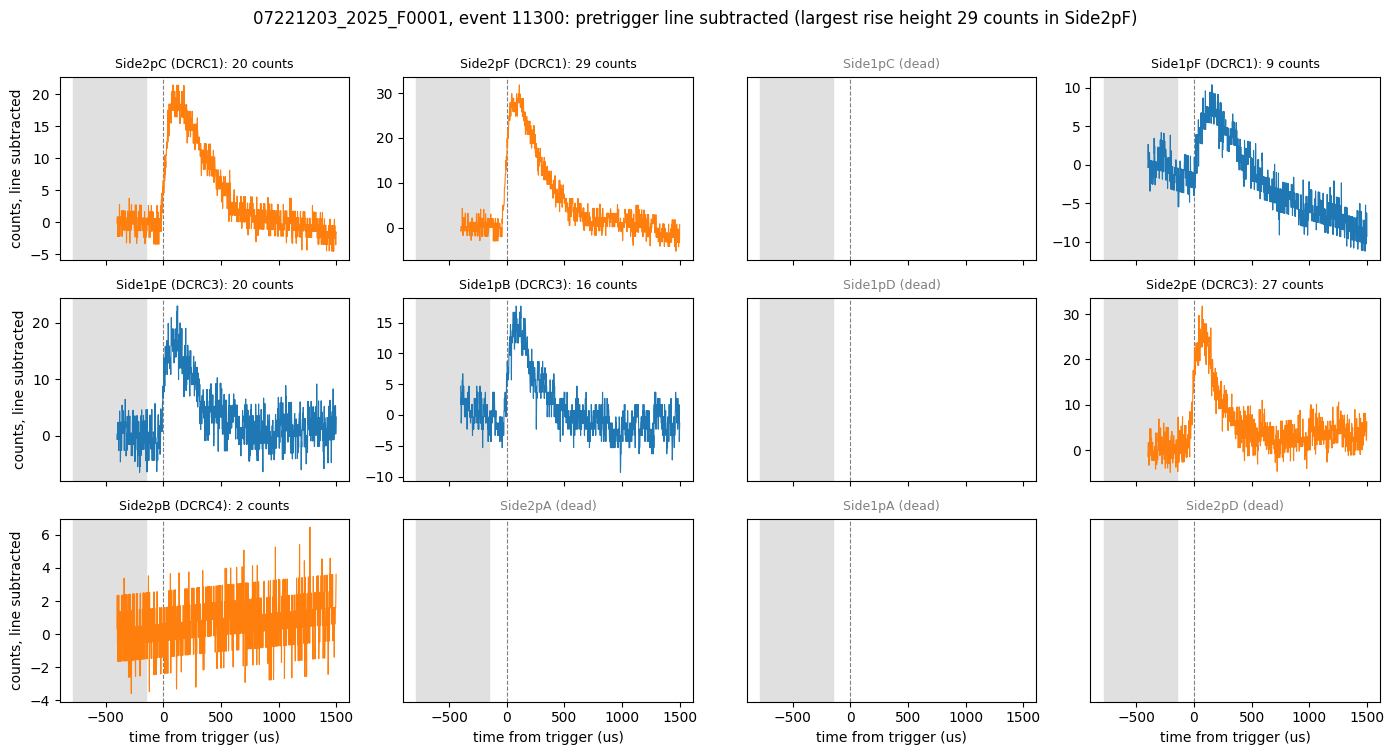

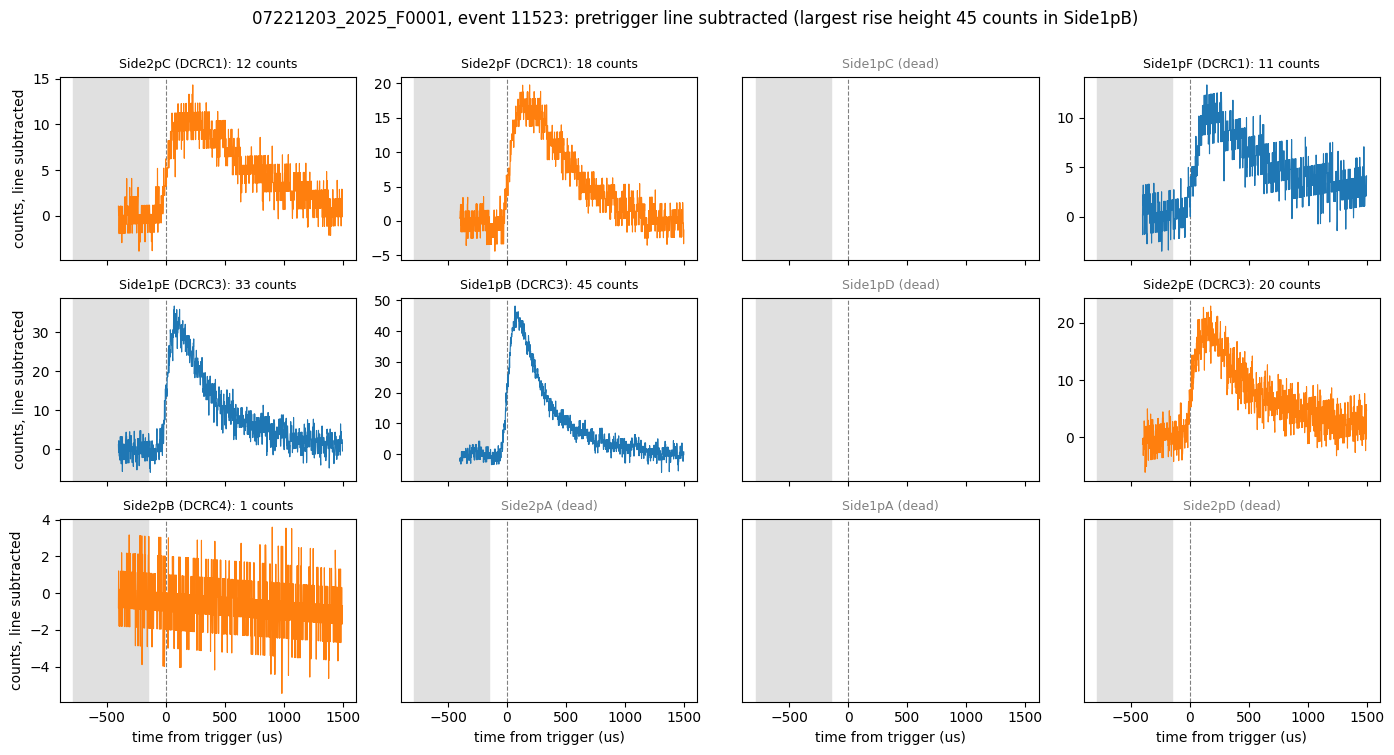

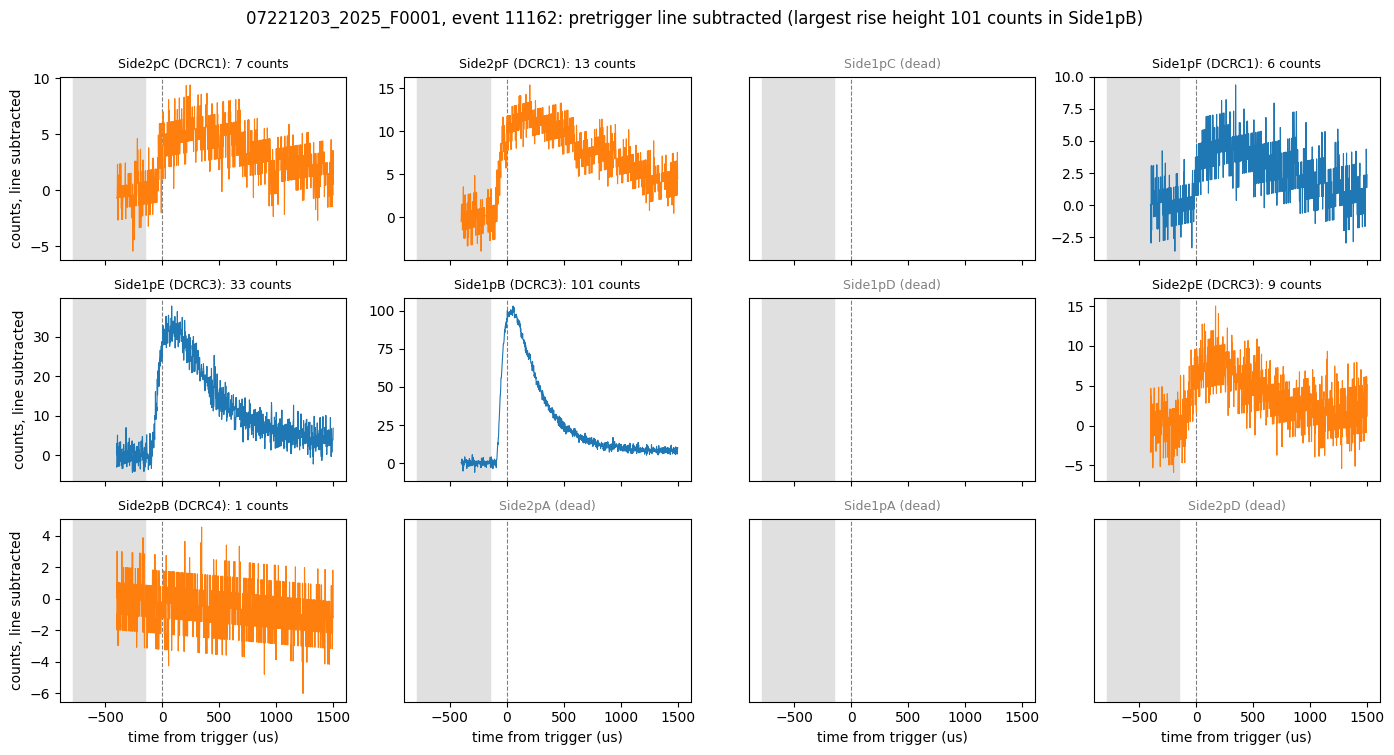

In [7]:
N_EVENTS = 3
EVENTS = None                      # or a list of event numbers, e.g. [11095, 11221]
PLOT_US = (-400, 1500)             # part of the trace to draw, microseconds from the trigger

event_numbers = np.array([int(pio.event_id(i)) for i in det_ids[0]])
sel = np.flatnonzero(small)
if EVENTS is None:
    order = sel[np.argsort(amp_max[sel])]                                  # selected events, smallest height first
    chosen = order[np.linspace(0, len(order) - 1, N_EVENTS + 2).astype(int)[1:-1]]
else:
    chosen = np.array([np.flatnonzero(event_numbers == ev)[0] for ev in EVENTS])

def subtract_pretrigger_line(traces, config=config_500):
    """Fit a straight line to the pretrigger samples (after the glitch, up to FIT_END) and subtract it from the whole trace. Returns the traces and the lines."""
    traces = np.asarray(traces, dtype=float)
    g = config.glitch_samples
    x = np.arange(traces.shape[-1])
    slope, intercept = np.polyfit(x[g:FIT_END], traces[..., g:FIT_END].T, 1)
    line = slope[..., None] * x + intercept[..., None]
    return traces - line, line

# the chosen events' traces in every channel (the dead channels stay empty)
chosen_traces = {}
for key in KEYS:
    if key in dead:
        continue
    _, p = pio.load_channel_batch(cdms, det_ids[key[0]], key[1])
    chosen_traces[key] = p[chosen]

n_samples = chosen_traces[working[0]].shape[-1]
t_us = (np.arange(n_samples) - config_500.pretrigger_samples) * config_500.sample_period_s * 1e6
t_fit = (np.array([config_500.glitch_samples, FIT_END]) - config_500.pretrigger_samples) * config_500.sample_period_s * 1e6
show = (t_us >= PLOT_US[0]) & (t_us <= PLOT_US[1])

for n, i in enumerate(chosen):
    fig, axes = plt.subplots(3, 4, figsize=(14, 7.5), sharex=True)
    for (det, ch), ax in zip(KEYS, axes.flat):
        ax.axvspan(*t_fit, color="0.88", zorder=0)
        ax.axvline(0, color="0.5", linestyle="--", linewidth=0.8)
        if (det, ch) in dead:
            ax.set_title(f"{pch.channel_name(det, ch)} (dead)", fontsize=9, color="0.5")
            ax.set_yticks([])
            continue
        flat, _ = subtract_pretrigger_line(chosen_traces[(det, ch)][n][None, :])
        ax.plot(t_us[show], flat[0][show], linewidth=0.8, color="C0" if pch.channel_info(det, ch).side == 1 else "C1")
        ax.set_title(f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc}): {amp[(det, ch)][i]:.0f} counts", fontsize=9)
    for ax in axes[-1]:
        ax.set_xlabel("time from trigger (us)")
    for ax in axes[:, 0]:
        ax.set_ylabel("counts, line subtracted")
    fig.suptitle(f"{DUMP}, event {event_numbers[i]}: pretrigger line subtracted (largest rise height {amp_max[i]:.0f} counts in {name(max_channel[i])})", y=1.0)
    fig.tight_layout()
    fig.savefig(FIGDIR / f"small-trigger-event{event_numbers[i]}-all-channels-{DUMP}.png", dpi=150, bbox_inches="tight")
    plt.show()